In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [10]:
set_size = pd.read_csv('results_final/20260217/sensitivity_analysis_directions_set_size.csv')
set_size_std = pd.read_csv('results_final/20260217/sensitivity_analysis_directions_set_size_std.csv')
cov = pd.read_csv('results_final/20260217/sensitivity_analysis_directions_cov.csv')
cov_std = pd.read_csv('results_final/20260217/sensitivity_analysis_directions_cov_std.csv')

<AxesSubplot: xlabel='confidence'>

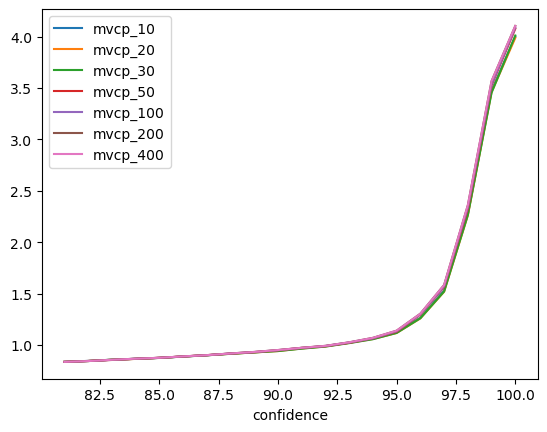

In [7]:
set_size.set_index('confidence').plot()

<AxesSubplot: xlabel='confidence'>

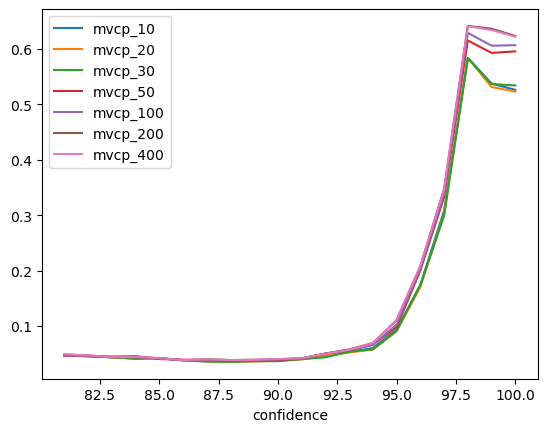

In [11]:
set_size_std.set_index('confidence').plot()

<AxesSubplot: xlabel='confidence'>

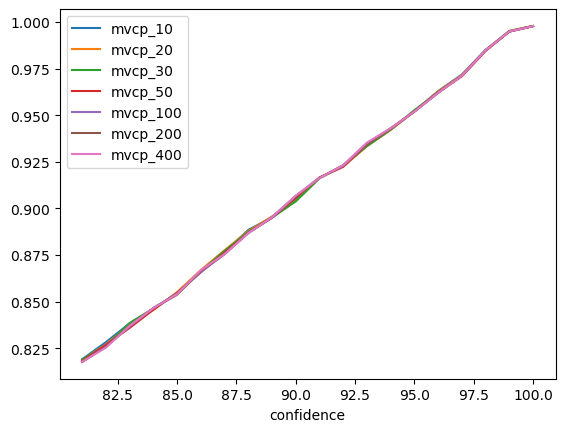

In [9]:
cov.set_index('confidence').plot()

<AxesSubplot: xlabel='confidence'>

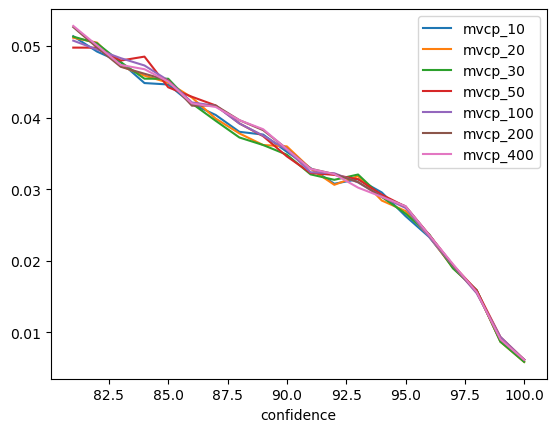

In [12]:
cov_std.set_index('confidence').plot()

In [71]:
set_size = pd.read_csv('results_final/20260217/sensitivity_analysis_cal_prop_set_size.csv')
set_size_std = pd.read_csv('results_final/20260217/sensitivity_analysis_cal_prop_set_size_std.csv')
cov = pd.read_csv('results_final/20260217/sensitivity_analysis_cal_prop_cov.csv')
cov_std = pd.read_csv('results_final/20260217/sensitivity_analysis_cal_prop_cov_std.csv')

In [72]:
p_list = []
for p in ([.10, .20, .30, .50, .80]):
    q = 1-.16/(1-p)
    #print(p, q*(1-p), 530*(1-p)*(1-q))
    
    p1, p2 = round(p/(p+q*(1-p)),2), round(q*(1-p)/(p+q*(1-p)), 2)
    #print(p1, p2)
    p_list.append([p1, p2])

In [82]:
[[int(100*p[0]), int(100*p[1])]for p in p_list]

[[12, 88], [24, 76], [36, 64], [60, 40], [95, 5]]

In [78]:
set_size.to_csv('results_final/20260218/sensitivity_analysis_cal_prop_set_size.csv')

In [79]:
cov.to_csv('results_final/20260218/sensitivity_analysis_cal_prop_cov.csv')

<AxesSubplot: xlabel='confidence'>

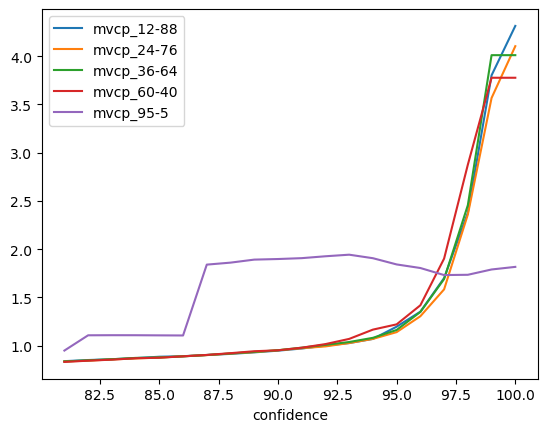

In [74]:
set_size = set_size.set_index('confidence')
set_size.columns = ['mvcp_'+str(int(100*p[0]))+'-'+str(int(100*p[1])) for p in p_list]
set_size.plot()

<AxesSubplot: xlabel='confidence'>

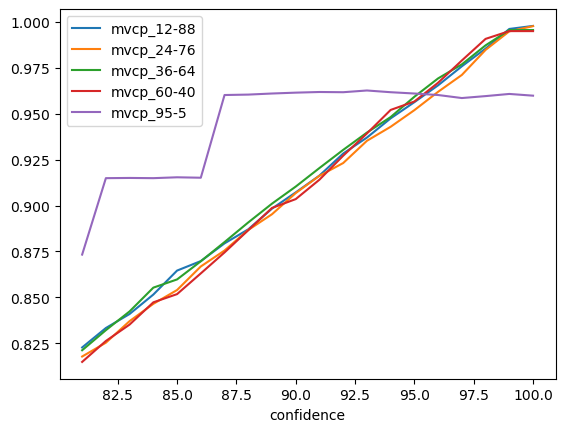

In [76]:
cov = cov.set_index('confidence')
cov.columns = ['mvcp_'+str(int(100*p[0]))+'-'+str(int(100*p[1])) for p in p_list]
cov.plot()

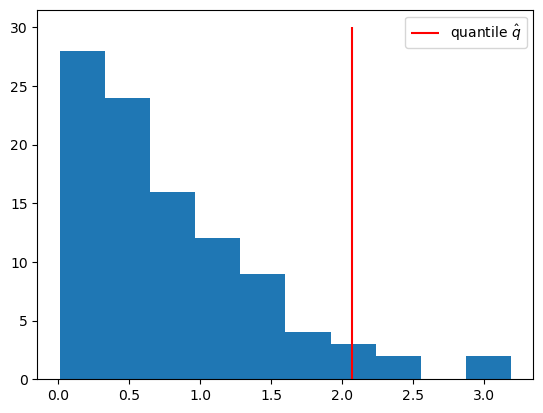

In [56]:
data = np.abs(np.random.normal(size=100))
q = np.quantile(data, .95)
_ = plt.hist(data)
_ = plt.vlines(q, 0, 30, color='red', label='quantile $\hat{q}$')
_ = plt.legend()

In [68]:
envelopes = pd.read_csv('results_final/20260218/sensitivity_analysis_directions_envelopes.csv')
del envelopes['Unnamed: 0']

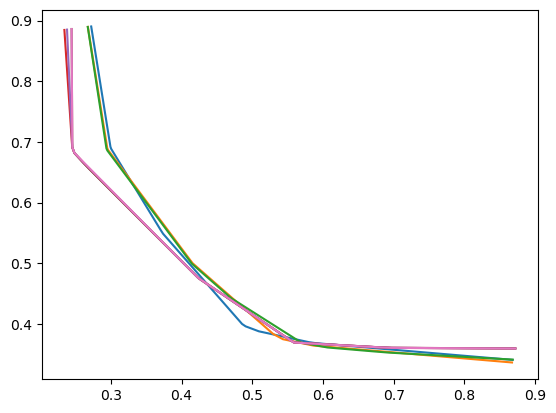

In [69]:
for i in range(7):
    plt.plot(
        envelopes.iloc[:,2*i],
        envelopes.iloc[:,2*i+1]
            )
    